# Fase 1 · Etapa 1.2 — Conferência de unidades e do mapeamento de canais (inclui C9)

> **Bases de dados usadas:**
> * **Dados do pesquisador:** os 156 CSVs (`data/catalog.yaml`) e os arquivos `.task` do
>   NI (Al e FV alinhado, 21/11/2024).
> * **Referências externas:** NI 9234 (±5 V), PCB 352C33 (100 mV/g nominal, ±50 g,
>   5,8 g), PCB 086C03 (2,25 mV/N, massa do martelo 0,16 kg — pcb.com); massas
>   específicas nominais da literatura listadas em `configs/data_sources.yaml`
>   (aço 7850, Al 2700, PMMA 1190 kg/m³) — **só** para a checagem de ordem de grandeza.
> * Dimensões das barras: Tabela 1 do TCC (pesquisador).

**Pergunta:** os números dos arquivos estão mesmo em g (aceleração) e N (força), na
escala certa? O cabeçalho diz que sim (Etapa 1.1: 156/156 com `g | g | N`), mas um
cabeçalho só repete o que foi configurado. Aqui a escala é testada contra a física,
por três caminhos independentes:
1. **piso de ruído** igual entre sessões → a sensibilidade configurada não mudou;
2. **impulso do martelo** → velocidade do martelo plausível para um golpe manual;
3. **linha de massa** da FRF livre-livre → nível compatível com 1/massa da viga.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

from dampid.eda import quality as q
from dampid.io.catalog import load_catalog
from dampid.io.ni_csv import read_ni_csv
from dampid.io.units import G0, to_si

from dampid.eda.survey import survey_catalog

cat = load_catalog("data/catalog.yaml")
src = yaml.safe_load(open("configs/data_sources.yaml", encoding="utf-8"))
# Levantamento de todas as métricas por registro (usado pelas Etapas 1.2–1.5); regenerável.
survey_catalog(cat).to_csv("data/processed/fase1_survey.csv", index=False)
sv = pd.read_csv("data/processed/fase1_survey.csv")
c2 = sv[sv.campaign == 2].copy()
date = {e.id: e.timestamp[:10] for e in cat.entries}
c2["data"] = c2["id"].map(date)

## 1. Piso de ruído por sessão
Com acoplamento AC e sensores IEPE, o ruído de fundo de um canal (em volts) depende do
sensor e do NI 9234, não do corpo de prova. Se a sensibilidade configurada fosse
diferente numa sessão, o ruído **em g ou N** mudaria na mesma proporção. Medida: menor
RMS em janelas de 10 ms do registro (trecho mais quieto) e σ robusto do canal de força.
O aço fica de fora da comparação do acelerômetro: ele nunca fica quieto (Etapa 1.3).

In [2]:
noise = (c2[c2.config != "LL_ACO"]
         .groupby(["data", "config"])[["a0_min_strms", "a1_min_strms", "F_noise_sigma"]]
         .median())
noise_mg = noise.copy()
noise_mg[["a0_min_strms", "a1_min_strms"]] *= 1e3
noise_mg.columns = ["Acel 1: ruído [mg rms]", "Acel 2: ruído [mg rms]", "Força: σ [N]"]
print(noise_mg.round(3).to_string())
by_date = c2[c2.config != "LL_ACO"].groupby("data")[["a0_min_strms", "a1_min_strms", "F_noise_sigma"]].median()
print("\nmediana por sessão:\n", (by_date * [1e3, 1e3, 1]).round(3).to_string())
ratio = by_date.loc["28/11/2024"] / by_date.loc["21/11/2024"]
print("\nrazão 28/11 ÷ 21/11:", ratio.round(2).to_dict())

                                Acel 1: ruído [mg rms]  Acel 2: ruído [mg rms]  Força: σ [N]
data       config                                                                           
21/11/2024 LL_ACRILICO                           0.449                   0.470         0.031
           LL_AL                                 0.511                   0.412         0.025
           LL_FIB_VIDRO_0                        0.505                   0.750         0.028
           LL_FIB_VIDRO_90                       0.562                   0.641         0.025
28/11/2024 LL_FIB_CARBONO                        0.444                   0.484         0.027
           LL_PLA_CAVERNA                        0.462                   0.527         0.025
           LL_PLA_LONGARINA_0                    0.617                   0.480         0.035
           LL_PLA_LONGARINA_90                   0.630                   0.515         0.030

mediana por sessão:
             a0_min_strms  a1_min_strms  F_noise_

## 2. Impulso do martelo → velocidade do martelo
Para um choque curto, o impulso J = ∫F dt é a variação de quantidade de movimento do
martelo: J = m_h Δv, com Δv entre v (choque plástico) e 2v (choque elástico). Com
m_h = 0,16 kg (PCB 086C03), a velocidade de impacto fica entre J/(2 m_h) e J/m_h.
Um golpe manual de ensaio modal tem algo como 0,2–2 m/s. Se a força estivesse em outra
escala (por exemplo, volts lidos como N, ×1/444), as velocidades sairiam absurdas.

In [3]:
m_h = 0.16
vel = c2.groupby("config")["F_impulse_Ns"].median().to_frame("J [N·s]")
vel["v_min [m/s]"] = vel["J [N·s]"] / (2 * m_h)
vel["v_max [m/s]"] = vel["J [N·s]"] / m_h
vel["F_pico [N]"] = c2.groupby("config")["F_peak_N"].median()
vel["F_pico/fundo de escala"] = c2.groupby("config")["F_peak_over_fs"].max()
print(vel.round(3).to_string())

                     J [N·s]  v_min [m/s]  v_max [m/s]  F_pico [N]  F_pico/fundo de escala
config                                                                                    
LL_ACO                 0.088        0.273        0.547      30.841                   0.101
LL_ACRILICO            0.022        0.070        0.140      19.494                   0.011
LL_AL                  0.044        0.137        0.275      11.693                   0.013
LL_FIB_CARBONO         0.062        0.193        0.387      40.066                   0.029
LL_FIB_VIDRO_0         0.057        0.179        0.358      14.032                   0.011
LL_FIB_VIDRO_90        0.072        0.225        0.450      19.378                   0.014
LL_PLA_CAVERNA         0.027        0.085        0.169       6.661                   0.004
LL_PLA_LONGARINA_0     0.044        0.136        0.272      32.370                   0.024
LL_PLA_LONGARINA_90    0.047        0.146        0.292      36.224                   0.021

## 3. Linha de massa nas barras livre-livre
Entre os modos de suspensão e o 1º modo elástico, uma estrutura livre se move como corpo
rígido. Para uma viga uniforme, com força em x_f e sensor em x_r (medidos a partir do
centro, na linha média), a acelerância de corpo rígido é

A_rb = (1/m)·(1 + 12 x_f x_r / L²) = κ/m,  com κ ∈ [−2, 4] (de extremidades opostas a
ponto colocado na extremidade; κ = 1 se a força ou o sensor está no centro).

Pontos fora da linha média somam a rotação em torno do eixo longitudinal e κ pode chegar
a ~7 nos cantos. Não conhecemos as posições, então o teste é de **ordem de grandeza**:
κ = |A|·m tem de cair em 0,5–7. Um erro de unidade (g lido como m/s², força sem a
sensibilidade do martelo) empurraria κ para ~0,1 ou ~20–400.

Estimativa de |A|: mediana de |H| (H = a/F de um registro, janela retangular — estimador de
EDA, não o da Fase 2) entre 30 e 70 Hz, acima da suspensão (~15–25 Hz) e bem abaixo de
f₁ ≈ 152–158 Hz. A rigidez dos modos elásticos ainda contamina essa faixa em ~10–30 %
(curva de |H| subindo para f₁), o que basta para uma checagem de ordem de grandeza.

In [4]:
geo = {k: v["geometry"] for k, v in src["specimens"].items()}
rho = {k: v.get("density_nominal") for k, v in src["specimens"].items()}
m_s = (0.0058, 0.0120)  # massa por conjunto sensor: só o sensor .. sensor + base PLA + cera + cabo (palpite de faixa, TODO medir)
rows, curves = [], {}
for cfg, spec in [("LL_ACO", "ACO"), ("LL_AL", "AL"), ("LL_ACRILICO", "ACRILICO")]:
    g = geo[spec]
    V = g["L_mm"] * g["b_mm"] * g["h_mm"] * 1e-9
    m_lo = rho[spec]["range"][0] * V + 2 * m_s[0]
    m_hi = rho[spec]["range"][1] * V + 2 * m_s[1]
    band = (30, 70) if spec != "ACRILICO" else (10, 20)
    lev = {0: [], 1: []}
    for e in cat.by_config()[cfg]:
        r = read_ni_csv("data/raw/" + e.path)
        fs = r.fs_hz
        P = q.find_pulses(r.data[2], fs)
        p = P[q.main_pulse(P)]
        n = int(1.9 * fs)
        for k in (0, 1):
            f, H = q.quick_h1(r.data[2], to_si(r.data[k], "g")[0], fs, p.i_start, n)
            sel = (f >= band[0]) & (f <= band[1])
            lev[k].append(np.median(np.abs(H[sel])))
            if e.repetition in (1, 2, 3, 4):
                curves.setdefault(cfg, []).append((k, f, H))
    for k in (0, 1):
        A = np.median(lev[k])
        rows.append({"config": cfg, "canal": f"Acel {k + 1}", "faixa [Hz]": band,
                     "|A| mediana [(m/s²)/N]": round(A, 2),
                     "disp. entre rep. [%]": round(100 * np.std(lev[k]) / A, 1),
                     "m nominal [kg]": f"{m_lo:.3f}–{m_hi:.3f}",
                     "κ = |A|·m": f"{A * m_lo:.2f}–{A * m_hi:.2f}"})
ml = pd.DataFrame(rows)
print(ml.to_string(index=False))

     config  canal faixa [Hz]  |A| mediana [(m/s²)/N]  disp. entre rep. [%] m nominal [kg] κ = |A|·m
     LL_ACO Acel 1   (30, 70)                    4.67                  26.2    0.372–0.398 1.74–1.86
     LL_ACO Acel 2   (30, 70)                    3.98                  21.0    0.372–0.398 1.48–1.58
      LL_AL Acel 1   (30, 70)                   14.50                   6.3    0.143–0.163 2.07–2.36
      LL_AL Acel 2   (30, 70)                   12.25                   4.6    0.143–0.163 1.75–2.00
LL_ACRILICO Acel 1   (10, 20)                    8.37                   7.5    0.064–0.078 0.53–0.65
LL_ACRILICO Acel 2   (10, 20)                    8.07                   9.8    0.064–0.078 0.51–0.63


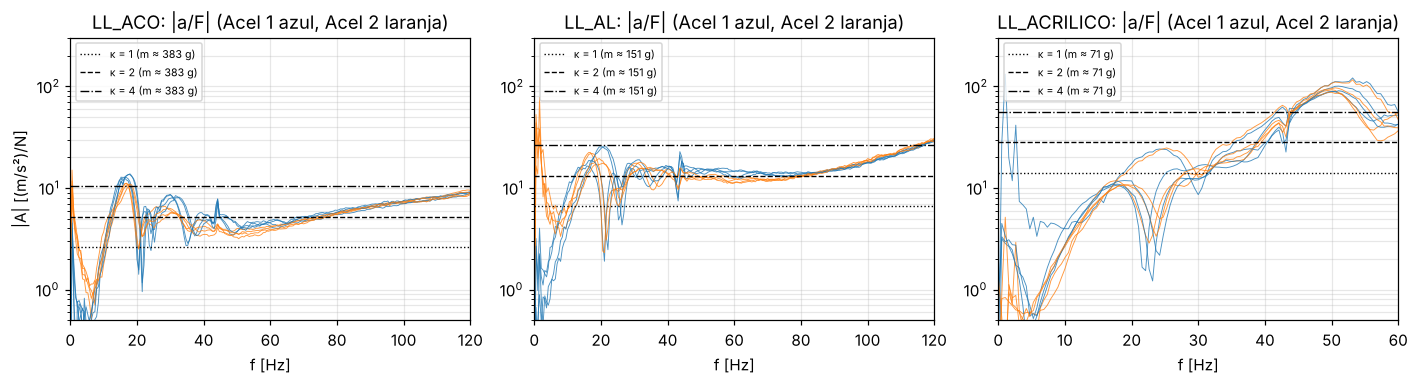

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, cfg, spec in zip(axs, ["LL_ACO", "LL_AL", "LL_ACRILICO"], ["ACO", "AL", "ACRILICO"], strict=True):
    g = geo[spec]
    V = g["L_mm"] * g["b_mm"] * g["h_mm"] * 1e-9
    m_mid = rho[spec]["value"] * V + 2 * 0.009
    for k, f, H in curves[cfg]:
        ax.semilogy(f, np.abs(H), color=f"C{k}", lw=0.6, alpha=0.8)
    for kap, ls in [(1, ":"), (2, "--"), (4, "-.")]:
        ax.axhline(kap / m_mid, color="k", ls=ls, lw=0.9, label=f"κ = {kap} (m ≈ {m_mid*1e3:.0f} g)")
    ax.set_xlim(0, 120 if spec != "ACRILICO" else 60)
    ax.set_ylim(0.5, 300)
    ax.set_title(f"{cfg}: |a/F| (Acel 1 azul, Acel 2 laranja)")
    ax.set_xlabel("f [Hz]")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=7, loc="upper left")
axs[0].set_ylabel("|A| [(m/s²)/N]")
plt.tight_layout()

Leitura: aço e alumínio têm um patamar entre ~30 e ~80 Hz, onde κ ≈ 1,5–2,4 com as massas
nominais — dentro da faixa física e igual para as duas barras (mesma montagem). No
**acrílico não há patamar**: f₁ (≈ 40–50 Hz) fica perto demais dos modos de suspensão
(≈ 15–25 Hz) e o valor da tabela (κ ≈ 0,5–0,65) **não é uma linha de massa** — não serve
para a checagem.

**Sinal da linha de massa.** A parte real de a/F abaixo de f₁ tem sinal definido pela
geometria (κ > 0 colocado; κ < 0 em extremidades opostas) e pela orientação do sensor.
O sinal medido é informação sobre a montagem, que o pesquisador pode conferir com as
fotos:

In [6]:
sig = []
for cfg in ["LL_ACO", "LL_AL", "LL_ACRILICO", "LL_FIB_VIDRO_0", "LL_FIB_VIDRO_90",
            "LL_PLA_CAVERNA", "LL_PLA_LONGARINA_0", "LL_PLA_LONGARINA_90"]:
    band = {"LL_ACRILICO": (10, 20), "LL_PLA_LONGARINA_0": (60, 200),
            "LL_PLA_LONGARINA_90": (60, 200), "LL_PLA_CAVERNA": (20, 40)}.get(cfg, (30, 70))
    vals = {0: [], 1: []}
    for e in cat.by_config()[cfg]:
        r = read_ni_csv("data/raw/" + e.path)
        fs = r.fs_hz
        P = q.find_pulses(r.data[2], fs)
        p = P[q.main_pulse(P)]
        n = min(int(1.9 * fs), r.n_samples - p.i_start)
        for k in (0, 1):
            f, H = q.quick_h1(r.data[2], to_si(r.data[k], "g")[0], fs, p.i_start, n)
            sel = (f >= band[0]) & (f <= band[1])
            vals[k].append(np.median(np.cos(np.angle(H[sel]))))
    sig.append({"config": cfg, "faixa [Hz]": band,
                "cos(fase) Acel 1": round(np.median(vals[0]), 2),
                "cos(fase) Acel 2": round(np.median(vals[1]), 2)})
print(pd.DataFrame(sig).to_string(index=False))

             config faixa [Hz]  cos(fase) Acel 1  cos(fase) Acel 2
             LL_ACO   (30, 70)             -0.99             -0.99
              LL_AL   (30, 70)             -0.96             -0.99
        LL_ACRILICO   (10, 20)              0.85              0.75
     LL_FIB_VIDRO_0   (30, 70)              0.93              0.92
    LL_FIB_VIDRO_90   (30, 70)             -0.95             -0.97
     LL_PLA_CAVERNA   (20, 40)             -0.89             -0.94
 LL_PLA_LONGARINA_0  (60, 200)             -1.00             -1.00
LL_PLA_LONGARINA_90  (60, 200)             -1.00             -0.64


## 4. C9 — 1ª campanha (`exp_5/`): o que está em Input 1 e Input 2?
Cabeçalho: `Input 0 [g] | Input 1 [g] | Input 2 [N]`. O legado lê Input 1 como força.
Teste de hipóteses com a forma dos pulsos (±1 ms em torno do pulso principal de Input 1):

| Hipótese | Previsão |
|---|---|
| H-a: mesmo sinal elétrico ligado nas duas entradas (T de BNC), escalas diferentes | correlação ≈ 1,000, razão Input1/Input2 constante = S₂/S₁ em todos os arquivos |
| H-b: acelerômetro no martelo (Input 1) + célula de força do martelo (Input 2) | forma quase igual (a = F/m_h), razão ≈ 1/(m_h g₀) constante, desvios na base (sensor de aceleração saturando/recuperando) |
| H-c: dois transdutores de força independentes | forma parecida, razão qualquer |

In [7]:
rows = []
for e in [x for x in cat.entries if x.campaign == 1]:
    r = read_ni_csv("data/raw/" + e.path)
    fs = r.fs_hz
    a, b = r.data[1], r.data[2]
    P = q.find_pulses(a, fs)
    m = P[q.main_pulse(P)]
    lo, hi = m.i_start - int(1e-3 * fs), m.i_end + int(1e-3 * fs)
    A = a[lo:hi] - np.median(a[:2000])
    B = b[lo:hi] - np.median(b[:2000])
    sigB = q.robust_sigma(b)
    rows.append({
        "arquivo": e.id.replace("C1_", ""),
        "pico In1 [g]": round(A.max(), 2),
        "pico In2 [N]": round(B.max(), 2),
        "In2 pico/ruído": round(B.max() / sigB, 0),
        "corr. forma": round(np.corrcoef(A, B)[0, 1], 4),
        "In1/In2 (pico)": round(A.max() / B.max(), 3) if B.max() > 20 * sigB else None,
        "m_h implícita [g] (H-b)": round(1e3 / (A.max() / B.max() * G0), 0) if B.max() > 20 * sigB else None,
        "In0 recorte (≥49 g)": int(np.sum(np.abs(r.data[0]) >= 49.0)),
    })
c9 = pd.DataFrame(rows)
with pd.option_context("display.width", 250):
    print(c9.to_string(index=False))
ok = c9["In1/In2 (pico)"].dropna()
print(f"\nIn1/In2 nos {len(ok)} arquivos com pulso em In2: {ok.min():.3f}–{ok.max():.3f} "
      f"(variação {100 * (ok.max() / ok.min() - 1):.0f} %); correlação de forma "
      f"{c9.loc[ok.index, 'corr. forma'].min():.3f}–{c9.loc[ok.index, 'corr. forma'].max():.3f}")

                      arquivo  pico In1 [g]  pico In2 [N]  In2 pico/ruído  corr. forma  In1/In2 (pico)  m_h implícita [g] (H-b)  In0 recorte (≥49 g)
       ACO_CC_mcentro_acentro         13.31         11.71           583.0       0.9945           1.136                     90.0                    0
   ACO_CC_mforacentro_acentro         14.28         12.42           644.0       0.9968           1.150                     89.0                    0
        ACO_CF_mcentro_aponta         21.44          0.08             6.0       0.1580             NaN                      NaN                    0
         ACO_CF_mponta_aponta         12.77          0.06             4.0       0.2645             NaN                      NaN                    0
  ACRILICO_CC_mcentro_acentro         10.45          9.01           291.0       0.9839           1.159                     88.0                    0
ACRILICO_CC_mforaponta_aponta          7.18          6.23           267.0       0.9897           1.153    

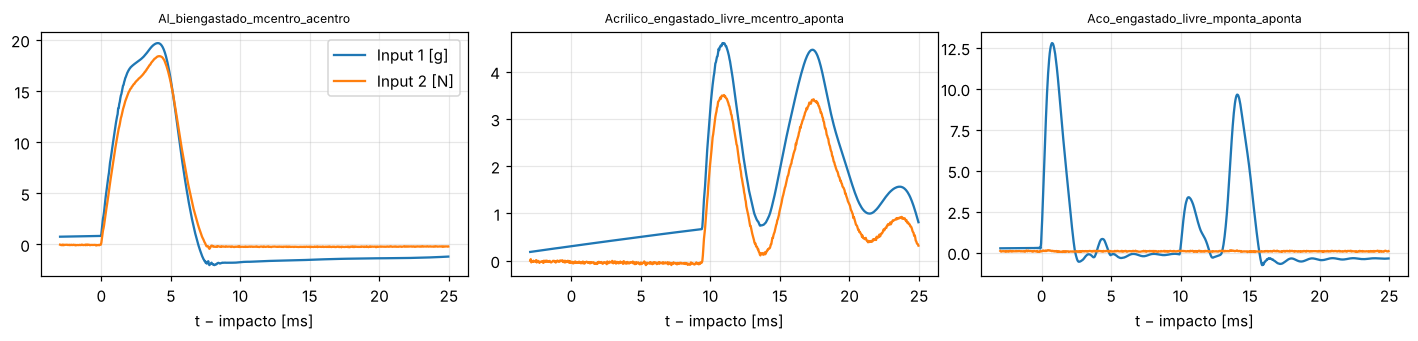

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, stem in zip(axs, ["Al_biengastado_mcentro_acentro", "Acrilico_engastado_livre_mcentro_aponta",
                          "Aco_engastado_livre_mponta_aponta"], strict=True):
    r = read_ni_csv(f"data/raw/exp_5/{stem}.csv")
    fs = r.fs_hz
    P = q.find_pulses(r.data[1], fs)
    m = P[q.main_pulse(P)]
    sl = slice(m.i_start - int(3e-3 * fs), m.i_start + int(25e-3 * fs))
    t = (np.arange(sl.stop - sl.start) - int(3e-3 * fs)) / fs * 1e3
    ax.plot(t, r.data[1][sl], label="Input 1 [g]")
    ax.plot(t, r.data[2][sl], label="Input 2 [N]")
    ax.set_title(stem, fontsize=8)
    ax.set_xlabel("t − impacto [ms]")
    ax.grid(alpha=0.3)
axs[0].legend()
plt.tight_layout()

## 5. Conclusões da etapa (resumidas no relatório 02)
Ver `docs/reports/fase1/02_unidades.md`.